# Chapter 10 과제 — 분류 분석으로 주문 취소 여부 예측하기

| 제출 정보 | 내용 |
| --- | --- |
| 이름 | 이성민 |
| GitHub ID | `minilee0307-dot` |
| 작성일 | 2026-11-12 |
| 최종 제출 URL | [실행 결과가 저장된 Notebook](https://github.com/minilee0307-dot/llm-data-analysis-study/blob/main/chapter10/chapter10.ipynb) |
| 제출 상태 | **COMPLETE**. eTL 2026-11-12 13:20(KST) 접수 확인 |

주문이 접수됐을 때 어떤 주문을 먼저 확인할지 정하는 이진 분류 실습이다. 공식 Notebook과 답안 양식을 바탕으로 셀을 재구성했다. 데이터에서 확인한 수치와 그 수치에 대한 해석을 각각 적었다. 작성, 실행, 검토에 Codex의 도움을 받았다.

[공식 실습 가이드](https://github.com/GilbertMoon/llm-data-analysis-course/blob/6105f42bd8294cb364dde6dcc2fee71c32e14794/practice/chapter10/chapter10.md), [공식 Notebook](https://github.com/GilbertMoon/llm-data-analysis-course/blob/6105f42bd8294cb364dde6dcc2fee71c32e14794/notebooks/ch10_llm_code_generation.ipynb), [답안 양식](https://github.com/GilbertMoon/llm-data-analysis-course/blob/6105f42bd8294cb364dde6dcc2fee71c32e14794/practice/chapter10/templates/chapter10_assignment.md)

## 1. 분류 문제 정의

- **질문:** 주문 정보와 장바구니 내용이 확정된 접수 시점에, 이 주문이 이후 `cancelled`로 끝날지 분류할 수 있을까?
- **분석 단위:** 주문 한 건. 한 주문의 상세 행은 주문 단위로 모은다.
- **타깃:** `is_cancelled`. 최종 상태 `completed`는 0, `cancelled`는 1이다. `refunded`와 기타 상태는 학습과 평가 대상에서 제외한다.
- **시점 가정:** 접수 당시의 수량, 단가, 결제수단, 주문 일자와 고객 프로필을 조회할 수 있다고 가정했다. CSV에는 접수 당시 값의 이력이 없어 이후 수정 여부를 확인할 수 없다.

### 나의 해석과 판단

환불을 0으로 묶으면 이미 다른 사건을 겪은 주문을 정상 완료와 같은 결과로 학습하게 된다. 이번 결과의 적용 범위는 완료와 취소 두 상태로 한정했다. 접수 시점의 장바구니 금액은 사용할 수 있다고 보되, 취소·환불을 거친 뒤 다시 계산된 금액이면 운영 입력에서 제외해야 한다.

## 2. Feature Contract와 누수 점검

| 입력 | 후보 컬럼과 기준 |
| --- | --- |
| 주문에서 계산한 숫자 | `item_count`는 상세 행 개수, `total_quantity`는 수량 합, `order_amount`는 `quantity × unit_price`의 합 |
| 접수 시점 숫자 | `order_month`, `order_dayofweek`, `age` |
| 접수 시점 범주 | `gender`, `city`, `payment_method` |
| 사용 제외 | `order_status`, `is_cancelled`, `cancel_reason`, `cancelled_at`, 환불·취소 후 값과 원본 식별자 `order_id`, `customer_id`, `product_id` |
| 품질 문제로 보류 | `days_since_signup`. 가입일이 주문일보다 늦은 기록을 점검한 뒤 모델 입력에서 제외 |

### 나의 해석과 판단

`order_status`는 정답을 만드는 데만 사용한다. 주문과 고객 ID는 병합용이다. `days_since_signup`는 접수 시점에 계산 가능한 후보였지만 날짜의 시간 관계가 맞지 않는 주문이 있었다. 원본 날짜와 주문을 보존하고, 문제 행만 0으로 채우거나 삭제하지 않고 해당 Feature 전체를 뺐다. Feature Audit과 실제 Pipeline에 넘긴 컬럼을 비교했다.

## 실행 환경과 입력 파일

공식 공통 원본 4개를 고정 커밋과 SHA-256으로 대조한다. 이 과제 입력은 `data/ch10/`에 준비한다. 원본에 통계 전처리를 미리 적용하지 않는다. 아래 분석 함수는 검증용 집계부터 Final Test까지 한 번 실행한다. 모델과 Threshold는 함수 내부에서 Validation으로 정하고 기록한 뒤 Test 확률을 계산한다.

In [1]:
from pathlib import Path
import subprocess
import sys

import numpy as np
import pandas as pd
import sklearn
from IPython.display import Image, Markdown, display

root = next(
    directory for directory in (Path.cwd(), *Path.cwd().parents)
    if (directory / 'scripts' / 'prepare_ch10_data.py').is_file()
)
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

from src.classification import run_classification_analysis

reports = root / 'reports'
images = root / 'chapter10' / 'images'
print(f'Python {sys.version.split()[0]} | pandas {pd.__version__} | '
      f'NumPy {np.__version__} | scikit-learn {sklearn.__version__}')
print(subprocess.check_output(
    [sys.executable, str(root / 'scripts' / 'prepare_ch10_data.py')],
    cwd=root,
    text=True,
))
result = run_classification_analysis(
    processed_dir=root / 'data/ch10/processed',
    raw_dir=root / 'data/ch10/raw',
    report_dir=reports,
    image_dir=images,
)

Python 3.14.3 | pandas 3.0.5 | NumPy 2.5.3 | scikit-learn 1.9.0


    dataset  rows  columns status
  customers   150        6   PASS
   products   100        4   PASS
     orders   300        5   PASS
order_items   764        5   PASS
                                 relationship  invalid_count status
  orders.customer_id -> customers.customer_id              0   PASS
      order_items.order_id -> orders.order_id              0   PASS
order_items.product_id -> products.product_id              0   PASS
Chapter 10 inputs: data/ch10/raw -> data/ch10/processed



## 3. 주문 단위 특징과 병합 검증

전처리에서 만든 `line_total`을 원본의 `quantity × unit_price` 별도 계산과 대조했다. 상세 행 개수, 수량 합, 금액 합을 주문별로 계산했다. `item_count`의 단위는 상세 행이고, `order_amount`는 접수 시점의 상세 금액 합이다. 취소 주문도 포함하므로 금액 합을 실현 매출로 해석할 수 없다. 집계표는 `one_to_one`, 고객표는 `many_to_one`으로 병합하고 indicator의 미매칭과 병합 전후 행 수를 확인했다.

In [2]:
display(result['data_quality_checks'])
display(result['merge_checks'])
display(result['raw_audit'])
display(result['feature_audit'])

,check_item,count
0,source_order_rows,300
1,source_detail_rows,764
2,binary_target_rows,248
3,excluded_status_rows,52
4,line_total_mismatch,0
5,order_feature_rows,300
6,order_feature_key_duplicates,0
7,signup_after_order_all,56
8,signup_after_order_binary,45
9,signup_lag_min_days_binary,-324


,merge,relation,before_rows,after_rows,unmatched_count,status
0,orders → order features,one_to_one,248,248,0,PASS
1,orders → customers,many_to_one,248,248,0,PASS


,check,rows_compared,passed
0,raw_status_frequency,300,True
1,raw_detail_line_total,764,True
2,raw_order_feature_values,300,True
3,raw_binary_order_feature_values,248,True
4,raw_binary_labels,248,True


,column,selected,role,reason
0,age,True,numeric,주문 접수 때 확인 가능한 고객 나이라고 가정
1,item_count,True,numeric,접수 시점에 확인 가능하다고 가정한 주문 상세 행 수
2,total_quantity,True,numeric,접수 시점에 확인 가능하다고 가정한 주문 수량 합계
3,order_amount,True,numeric,접수 시점에 확인 가능하다고 가정한 수량 × 단가 합계(원)
4,order_month,True,numeric,주문 접수일의 월
5,order_dayofweek,True,numeric,주문 접수일의 요일(월요일=0)
6,gender,True,categorical,주문 접수 시점 고객 프로필로 가정
7,city,True,categorical,주문 접수 시점 고객 프로필로 가정
8,payment_method,True,categorical,주문 접수 시 선택한 결제 수단이라고 가정
9,order_status,False,excluded,"사후 확정 상태, 타깃 정의에만 사용"


### 결과 관찰

공통 원본은 고객 150행, 상품 100행, 주문 300행, 주문 상세 764행이다. 원본 수량과 단가를 별도로 곱한 결과 전처리 금액과 불일치한 상세는 0건이었다. 이진 분류 범위의 상세는 636행이며 금액 합은 211,171,000원이다. 주문별 집계 키 중복과 두 병합 미매칭은 모두 0건이었다.

가입일이 주문일보다 늦은 주문은 전체 56건(완료 35건, 취소 10건, 환불 11건)이다. 이진 분류 범위에서는 45/248건(18.15%)이며 날짜 차이의 범위는 −324일에서 1,041일이었다. 공식 코드를 그대로 실행하면 이 범위의 음수 45건에서 중단됐다. 날짜 차이를 입력에서 제외한 뒤에도 대상 248건을 그대로 유지했다.

### 나의 해석과 판단

상세에 없는 주문을 금액 0으로 채우면 실제 금액이 0인 주문과 조인 실패를 구별하기 어렵다. 미매칭이 생길 때는 학습 전에 주문 상세 누락과 키 문제를 확인해야 한다. 가입일 오류는 프로필의 이력이 불확실하다는 신호이므로 날짜 차이를 쓰려면 원천 정의부터 확인해야 한다.

## 4. 클래스 비율

In [3]:
display(result['status_scope'])
display(result['target_distribution'])

,order_status,order_count,used_for_binary_target,class_label
0,completed,184,True,0
1,cancelled,64,True,1
2,refunded,52,False,<NA>


,is_cancelled,class_label,count,ratio
0,0,completed,184,0.741935
1,1,cancelled,64,0.258065


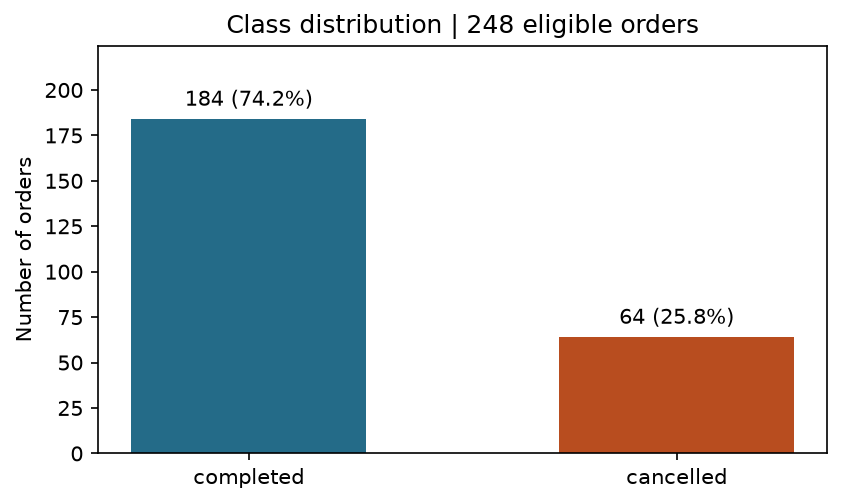

In [4]:
display(Image(filename=images / 'step02_class_ratio.png', alt='완료와 취소 클래스의 실제 건수와 비율'))

### 결과 관찰

300건 중 `completed` 184건, `cancelled` 64건, `refunded` 52건이었다. 분류 범위 248건에서 완료 74.19%, 취소 25.81%다. 그래프의 분모는 제외 후 248건이다. 환불 52건은 원본 상태 집계에 남아 있다.

### 나의 해석과 판단

전부 완료로 분류해도 전체 범위에서 정확도가 약 74%다. 취소를 한 건도 찾지 못해도 이렇게 나오므로 정확도 외에 취소 클래스의 Precision, Recall, F1을 봤다. 실제 검토 인력이 정해져 있으면 Precision과 검토 건수도 함께 확인해야 한다.

## 5. Train / Validation / Test와 전처리

주문 날짜, 숫자형 주문 ID 순서로 정렬했다. 주문 단위 `stratify`와 시드 42로 Final Test 20%를 먼저 떼고, 남은 데이터의 25%를 Validation으로 분리했다. Train에서만 수치형 중앙값 대체와 표준화, 범주형 최빈값 대체와 원핫 인코딩을 학습했다. 학습 시 못 본 범주는 `handle_unknown="ignore"`로 처리한다.

| 범위 | 역할 |
| --- | --- |
| Train | 각 후보 모델과 전처리 학습 |
| Validation | 기본 기준으로 모델 비교 후 선택 모델의 Threshold 선택 |
| Final Test | 고정한 모델·Threshold의 마지막 평가 |

In [5]:
display(result['split_summary'])
display(result['split_overlap'])
display(result['preprocessing_audit'])

,split,orders,completed,cancelled,cancelled_ratio
0,Train,148,110,38,0.256757
1,Validation,50,37,13,0.260000
2,Test,50,37,13,0.260000


,split_a,split_b,shared_orders,shared_customers,shared_dates
0,Train,Validation,0,32,15
1,Train,Test,0,26,17
2,Validation,Test,0,12,5


,model,check,train_rows,passed
0,Dummy Most Frequent,median,148,True
1,Dummy Most Frequent,scaler_mean,148,True
2,Dummy Most Frequent,scaler_variance,148,True
3,Dummy Most Frequent,scaler_fit_rows,148,True
4,Dummy Most Frequent,categorical_mode,148,True
5,Dummy Most Frequent,encoded_categories,148,True
6,Dummy Most Frequent,unknown_categories_ignored,148,True
7,Logistic Regression,median,148,True
8,Logistic Regression,scaler_mean,148,True
9,Logistic Regression,scaler_variance,148,True


### 결과 관찰

Train 148건(완료 110, 취소 38), Validation 50건(완료 37, 취소 13), Final Test 50건(완료 37, 취소 13)이다. 주문 ID의 집합 간 교집합은 모두 0건이다. Train과 Test에는 공통 고객 26명과 공통 주문 날짜 17일이 있다. 이 고객과 날짜의 식별값은 공개하지 않았다.

### 나의 해석과 판단

주문 중복 없이 각 집합에 두 클래스가 있는지 확인했다. Validation은 이미 선택에 사용했으므로 그 점수를 마지막 성능으로 볼 수 없다. 같은 고객의 서로 다른 주문이 여러 집합에 들어갈 수 있고 시간 순서도 섞인다. 실제 미래 주문에는 날짜순으로 한 번 더 검증하고, 신규 고객으로 범위를 넓힐 때는 고객 단위 분리 평가도 필요하다.

## 6. Dummy Baseline과 Validation 모델 비교

같은 Validation에서 Dummy Most Frequent, Logistic Regression(`max_iter=1000`), Random Forest(나무 200개, 시드 42)를 기본 예측 기준으로 비교했다. 두 학습 모델에는 `class_weight="balanced"`를 사용했다. 비Dummy 후보를 F1, Recall, Precision 내림차순, 이름 오름차순으로 정렬해 한 모델을 선택했다. 여기까지 Threshold 탐색 점수와 Final Test 성적은 선택에 쓰지 않았다.

In [6]:
display(result['validation_model_comparison'])

,model,evaluation_split,accuracy,precision,recall,f1,tn,fp,fn,tp
0,Dummy Most Frequent,validation,0.74,0.000000,0.000000,0.00,37,0,13,0
1,Logistic Regression,validation,0.72,0.466667,0.538462,0.50,29,8,6,7
2,Random Forest,validation,0.66,0.333333,0.307692,0.32,29,8,9,4


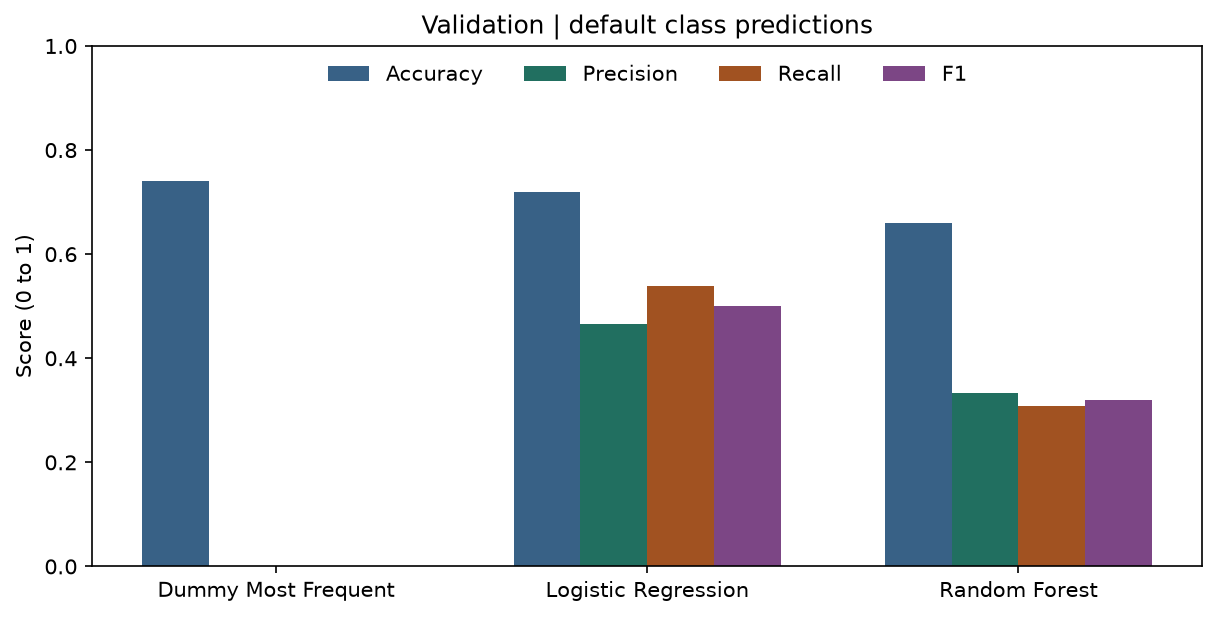

In [7]:
display(Image(filename=images / 'step03_baseline.png', alt='동일 Validation에서 Dummy와 두 후보의 지표 비교'))

### 결과 관찰

Dummy는 50건을 모두 완료로 분류해 Accuracy 0.7400, 취소 Precision, Recall, F1은 0이었다. 기본 기준에서 Logistic Regression은 Accuracy 0.7200, Precision 0.4667, Recall 0.5385, F1 0.5000이다. Random Forest의 F1은 0.3200이었다. Logistic Regression은 Dummy보다 정확도가 2%p 낮았고 취소는 13건 중 7건을 찾아 F1이 높았다. 이 단계의 선택은 Logistic Regression이다.

### 우선 지표와 이유

취소를 놓치면 확인 기회를 잃고, 정상 주문을 취소로 표시하면 확인 업무가 늘어난다. 두 오류 비용이 제공되지 않아 한쪽을 임의로 돈으로 환산하지 않고 양성 Precision과 Recall의 조화평균인 F1을 1순위로 뒀다. 동률에서는 우선 확인 목적에 맞게 Recall을 먼저 봤다. 선택 기준은 Validation 전체에 일관되게 적용했다.

## 7. Validation Threshold 비교와 선택 고정

선택 모델의 취소 확률에 `p ≥ Threshold`를 적용한다. 0.20부터 0.80까지 0.05 간격의 13개 기준을 비교했다. F1, Recall, Precision 순으로 선택하고 세 지표가 같으면 낮은 Threshold를 사용했다. 기준을 낮출 때 표시되는 주문은 줄어들지 않으므로 Recall과 알림 수를 함께 해석해야 한다.

In [8]:
display(result['threshold_metrics'])

,threshold,accuracy,precision,recall,f1,tn,fp,fn,tp
0,0.20,0.30,0.270833,1.000000,0.426230,2,35,0,13
1,0.25,0.34,0.282609,1.000000,0.440678,4,33,0,13
2,0.30,0.44,0.307692,0.923077,0.461538,10,27,1,12
3,0.35,0.52,0.333333,0.846154,0.478261,15,22,2,11
4,0.40,0.62,0.384615,0.769231,0.512821,21,16,3,10
5,0.45,0.70,0.450000,0.692308,0.545455,26,11,4,9
6,0.50,0.72,0.466667,0.538462,0.500000,29,8,6,7
7,0.55,0.76,0.545455,0.461538,0.500000,32,5,7,6
8,0.60,0.78,0.600000,0.461538,0.521739,33,4,7,6
9,0.65,0.74,0.500000,0.307692,0.380952,33,4,9,4


In [9]:
fixed = result['selection']
print(f"Validation 고정 | {fixed['model']} | Threshold {fixed['threshold']:.2f}")
print(f"선택 설정 SHA-256 | {result['selection_sha256']}")

Validation 고정 | Logistic Regression | Threshold 0.45
선택 설정 SHA-256 | dab41c42996f795a50a0cc3991f824b0945f31b69fd085cf3fb660f74ff6a0b0


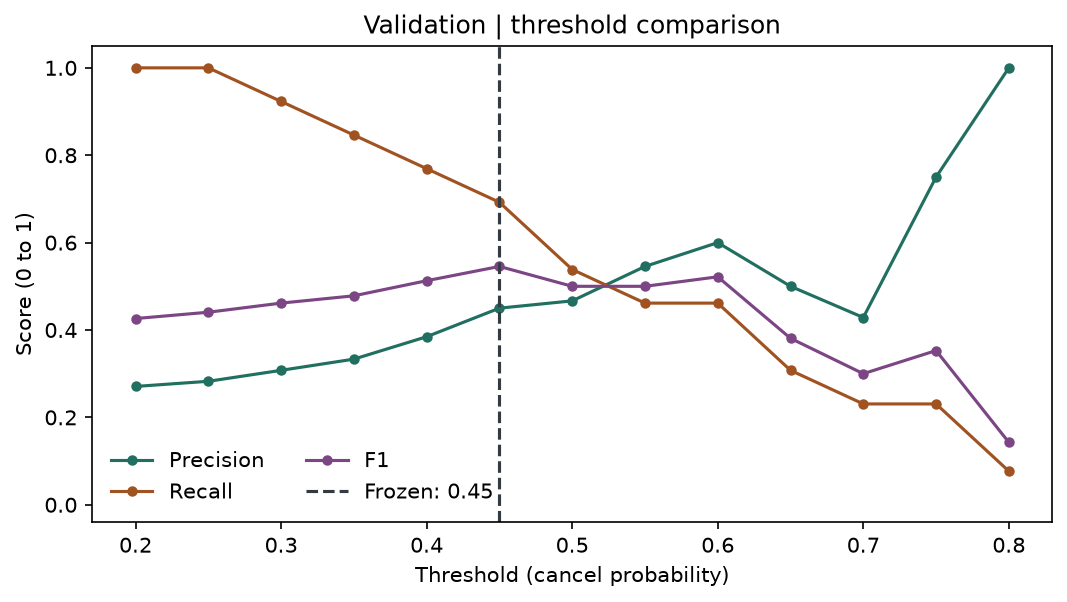

In [10]:
display(Image(filename=images / 'step05_threshold.png', alt='Validation Threshold에 따른 Precision, Recall, F1'))

### 결과 관찰

0.25에서는 취소 13건을 모두 찾았고 FP 33건, Precision 0.2826, F1 0.4407이었다. 기본 기준 0.50에서는 15건을 표시해 7건을 찾았다. 0.45에서는 20건을 표시해 9건을 찾았고, Precision 0.4500, Recall 0.6923, F1 0.5455였다. 0.60에서는 10건을 표시해 6건을 찾았고 F1은 0.5217이었다.

### 나의 해석과 판단

후보 중 F1이 가장 높아 0.45를 선택했다. 기본 기준보다 취소 2건을 더 찾는 대신 FP가 3건 늘었다. Validation에서도 취소 4건은 놓쳤다. 모델이 낸 점수를 실제 취소 확률로 해석하려면 별도의 확률 보정 검증이 필요하다.

### 선택 보호

Validation에서 선택한 모델과 Threshold를 설정 파일에 저장한 뒤 Final Test의 예측을 실행했다. Test 결과로 모델, Threshold, Feature, 분할 시드를 다시 선택하지 않았다. Threshold를 고르는 데 쓴 Validation과 최종 평가를 같은 집합으로 두면 선택 과정에서 우연히 높았던 지표까지 보고하게 된다.

## 8. Final Test와 FP/FN 해석

고정 설정의 Accuracy, Precision, Recall, F1과 혼동행렬이다. 실제 완료를 취소로 표시하면 FP, 실제 취소를 완료로 표시하면 FN이다. 양성은 항상 `cancelled=1`이다.

In [11]:
display(result['test_metrics'])
display(result['confusion_matrix'])

,model,evaluation_split,threshold,selection_status,accuracy,precision,recall,f1,tn,fp,fn,tp
0,Logistic Regression,test_final,0.45,frozen_before_test,0.6,0.315789,0.461538,0.375,24,13,7,6


,pred_completed,pred_cancelled
actual,,
actual_completed,24,13
actual_cancelled,7,6


In [12]:
metric_audit = result['metric_audit']
display(metric_audit.loc[metric_audit['evaluation'].eq('test_final:frozen_pair')])

,evaluation,metric,recalculated,observed,passed
128,test_final:frozen_pair,tn,24.000000,24.000000,True
129,test_final:frozen_pair,fp,13.000000,13.000000,True
130,test_final:frozen_pair,fn,7.000000,7.000000,True
131,test_final:frozen_pair,tp,6.000000,6.000000,True
132,test_final:frozen_pair,accuracy,0.600000,0.600000,True
133,test_final:frozen_pair,precision,0.315789,0.315789,True
134,test_final:frozen_pair,recall,0.461538,0.461538,True
135,test_final:frozen_pair,f1,0.375000,0.375000,True


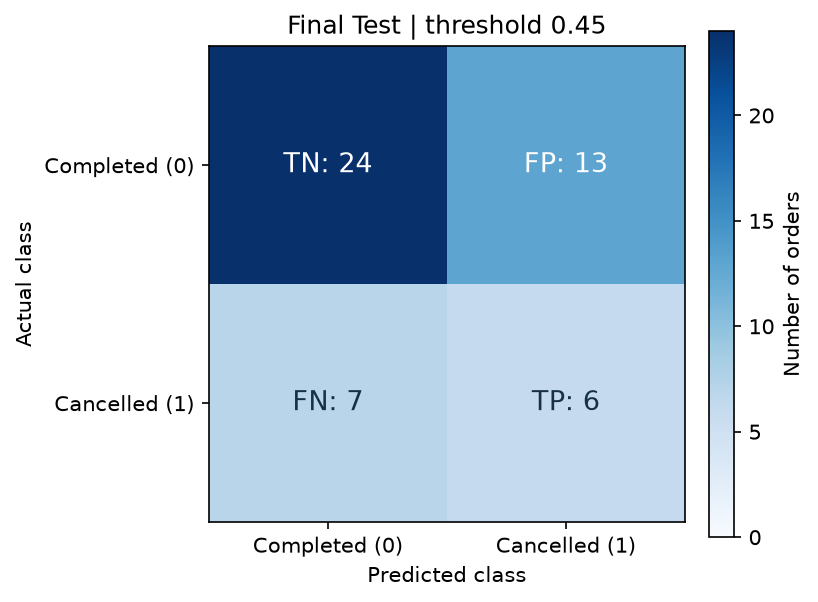

In [13]:
display(Image(filename=images / 'step06_confusion_matrix.png', alt='Final Test 실제 상태별 예측 건수'))

### 결과 관찰

Logistic Regression과 Threshold 0.45에서 Final Test 50건의 TN 24, FP 13, FN 7, TP 6이다. 같은 기준을 적용한 두 집합의 지표를 비교했다.

| 지표 | Validation | Final Test | Test − Validation |
| --- | ---: | ---: | ---: |
| Accuracy | 0.7000 | 0.6000 | −0.1000 |
| Precision | 0.4500 | 0.3158 | −0.1342 |
| Recall | 0.6923 | 0.4615 | −0.2308 |
| F1 | 0.5455 | 0.3750 | −0.1705 |

Final Test의 다수 클래스 기준 정확도는 37/50=0.7400이며 취소 탐지는 0건이다. 비교를 위해 Train에서 확인한 다수 클래스 예측을 집계에만 적용했다.

### 나의 해석과 판단

같은 Threshold에서 표시 건수는 Validation 20건, Test 19건으로 비슷했다. 실제 취소를 표시한 건수는 9건에서 6건으로 줄고 FP는 11건에서 13건으로 늘었다. 각 분할에 취소가 13건뿐이어서 이 정도 차이에도 Recall이 크게 움직인다. 같은 Validation에서 모델과 Threshold를 골랐으므로 Validation 성능이 선택 과정에서 높게 나타났을 가능성도 있다. 이 두 표본으로 성능 차이의 원인을 확정하거나 시간에 따른 변화라고 판단할 수 없다.

### 업무 의미와 한계

알림 19건 중 정상 주문 13건을 다시 확인하게 되고, 실제 취소 13건 중 7건은 표시되지 않는다. 이 실습의 목적은 취소 위험을 먼저 확인하는 것이고, 알림은 가벼운 내부 확인으로 가정했으므로 FN을 더 중요하게 봤다. 고객에게 직접 연락하거나 주문을 지연시키는 조치라면 FP 비용도 크다. 실제 확인 가능 건수, 검토 시간, 연락 시 고객 불편, 개입 효과를 알아야 업무용 Threshold를 정할 수 있다.

## 9. Internal / Public 결과 구분

오류를 추적할 때 필요한 원본 인덱스와 식별자는 로컬 Internal 자료에만 둔다. 공개 CSV와 Notebook에는 순번으로 만든 `record_id`, 실제·예측 클래스, 취소 확률, 모델, Threshold만 남긴다. `record_id`는 주문 키로 재사용하지 않는다.

In [14]:
public = result['prediction_result']
expected_columns = [
    'record_id', 'actual_is_cancelled', 'predicted_is_cancelled',
    'cancel_probability', 'model', 'threshold',
]
assert list(public.columns) == expected_columns
assert public['record_id'].is_unique
assert public['cancel_probability'].between(0, 1).all()
assert (public['predicted_is_cancelled'] ==
        (public['cancel_probability'] >= public['threshold']).astype(int)).all()
print(f'공개 컬럼 {len(expected_columns)}개 / 공개 예측 {len(public)}건')
display(public.head(3))

공개 컬럼 6개 / 공개 예측 50건


,record_id,actual_is_cancelled,predicted_is_cancelled,cancel_probability,model,threshold
0,test_0001,0,1,0.683535,Logistic Regression,0.45
1,test_0002,0,0,0.409431,Logistic Regression,0.45
2,test_0003,0,1,0.512531,Logistic Regression,0.45


## 10. 검증 근거와 재실행

저장소 루트에서 같은 Python 환경으로 실행한다.

```bash
python -m pip install -r requirements.txt
python scripts/prepare_ch10_data.py
python scripts/run_classification_analysis.py
```

Notebook과 스크립트는 동일한 분석 함수를 사용한다. 공식 답안 양식의 집계·검증 CSV를 다음에서 확인할 수 있다.

- [Target 비율](../reports/ch10_target_distribution.csv), [Feature Audit](../reports/ch10_feature_audit.csv), [병합 검증](../reports/ch10_merge_checks.csv), [데이터 품질](../reports/ch10_data_quality_checks.csv)
- [분할 요약](../reports/ch10_split_summary.csv), [Validation 모델 비교](../reports/ch10_validation_model_comparison.csv), [Threshold 비교](../reports/ch10_validation_threshold_metrics.csv)
- [Final Test 지표](../reports/ch10_test_metrics.csv), [혼동행렬](../reports/ch10_confusion_matrix.csv), [자동 Validation](../reports/ch10_classification_validation.csv)
- [공개 예측](../reports/ch10_classification_predictions.csv), [실행 요약](../reports/ch10_classification_summary.md), [선택 고정 파일](../reports/ch10_frozen_selection.json), [그래프 검산](../reports/ch10_graph_audit.csv)
- [클래스 비율 그림](images/step02_class_ratio.png), [기준선 비교 그림](images/step03_baseline.png), [Threshold 그림](images/step05_threshold.png), [혼동행렬 그림](images/step06_confusion_matrix.png)

두 스크립트를 별도 작업 폴더에서 새로 실행해 공개 산출물 26개와 로컬 내부 CSV 2개의 SHA-256이 일치함을 확인했다. 자동 Validation 18개, 원본 대조 5개, Train 전처리 검산 21개, 지표 검산 136개, 그래프 값 대조 4개가 통과했다.

In [15]:
display(result['validation'])

,check,value,status
0,exact_binary_scope_and_label,True,PASS
1,raw_inputs_reconciled,True,PASS
2,line_total_and_order_key,True,PASS
3,merges_preserve_rows_without_unmatched,True,PASS
4,features_have_no_target_ids_or_post_outcome,True,PASS
5,invalid_tenure_excluded_and_rows_preserved,True,PASS
6,split_complete_and_no_order_overlap,True,PASS
7,both_classes_in_every_split,True,PASS
8,preprocessing_statistics_match_train,True,PASS
9,selection_is_non_dummy_and_on_validation,True,PASS


### 자동 검증의 범위

PASS는 현재 자료에서 정한 데이터 처리와 계산 규칙을 만족했다는 뜻이다. 실제 미래 데이터에서도 성능이 유지되는지, 고객군별 오분류율 차이가 허용 가능한지, 알림을 보내는 조치가 취소율을 줄이는지는 별도 검증이 필요하다.

### 별도 구현과 대조

분석 함수를 호출하지 않는 별도 검토에서 원본 CSV를 `csv.DictReader`로 읽고 `Decimal`로 금액을 다시 계산했다. Train의 전처리 학습 통계와 모델 평가를 따로 계산해 같은 순서로 모델과 Threshold를 고정했다. 아래 코드는 그 검토에서 얻은 집계값과 제출 Pipeline의 출력값을 대조한다.

In [16]:
reference = {'status': {'cancelled': 64, 'completed': 184, 'refunded': 52},
 'split': {'train': [148, 110, 38], 'validation': [50, 37, 13], 'test': [50, 37, 13]},
 'models': {'Dummy Most Frequent': [0.74, 0.0, 0.0, 0.0, 37, 0, 13, 0],
            'Logistic Regression': [0.72,
                                    0.4666666666666667,
                                    0.5384615384615384,
                                    0.5,
                                    29,
                                    8,
                                    6,
                                    7],
            'Random Forest': [0.66, 0.3333333333333333, 0.3076923076923077, 0.32, 29, 8, 9, 4]},
 'thresholds': {0.2: [0.3, 0.2708333333333333, 1.0, 0.4262295081967213, 2, 35, 0, 13],
                0.25: [0.34, 0.2826086956521739, 1.0, 0.4406779661016949, 4, 33, 0, 13],
                0.3: [0.44,
                      0.3076923076923077,
                      0.9230769230769231,
                      0.46153846153846156,
                      10,
                      27,
                      1,
                      12],
                0.35: [0.52,
                       0.3333333333333333,
                       0.8461538461538461,
                       0.4782608695652174,
                       15,
                       22,
                       2,
                       11],
                0.4: [0.62,
                      0.38461538461538464,
                      0.7692307692307693,
                      0.5128205128205128,
                      21,
                      16,
                      3,
                      10],
                0.45: [0.7, 0.45, 0.6923076923076923, 0.5454545454545454, 26, 11, 4, 9],
                0.5: [0.72, 0.4666666666666667, 0.5384615384615384, 0.5, 29, 8, 6, 7],
                0.55: [0.76, 0.5454545454545454, 0.46153846153846156, 0.5, 32, 5, 7, 6],
                0.6: [0.78, 0.6, 0.46153846153846156, 0.5217391304347826, 33, 4, 7, 6],
                0.65: [0.74, 0.5, 0.3076923076923077, 0.38095238095238093, 33, 4, 9, 4],
                0.7: [0.72, 0.42857142857142855, 0.23076923076923078, 0.3, 33, 4, 10, 3],
                0.75: [0.78, 0.75, 0.23076923076923078, 0.35294117647058826, 36, 1, 10, 3],
                0.8: [0.76, 1.0, 0.07692307692307693, 0.14285714285714285, 37, 0, 12, 1]},
 'test': [0.6, 0.3157894736842105, 0.46153846153846156, 0.375, 24, 13, 7, 6],
 'selection': ['Logistic Regression', 0.45]}

In [17]:
metric_columns = ['accuracy', 'precision', 'recall', 'f1', 'tn', 'fp', 'fn', 'tp']
status_counts = result['status_scope'].set_index('order_status')['order_count']
assert status_counts.to_dict() == reference['status']

split_counts = result['split_summary'].set_index('split')
split_counts.index = split_counts.index.str.lower().str.replace('final ', '', regex=False)
for split, counts in reference['split'].items():
    assert split_counts.loc[split, ['orders', 'completed', 'cancelled']].tolist() == counts

model_metrics = result['validation_model_comparison'].set_index('model')
for model, values in reference['models'].items():
    np.testing.assert_allclose(model_metrics.loc[model, metric_columns].to_numpy(dtype=float), values, rtol=0, atol=1e-12)

threshold_metrics = result['threshold_metrics'].set_index('threshold')
for threshold, values in reference['thresholds'].items():
    np.testing.assert_allclose(threshold_metrics.loc[threshold, metric_columns].to_numpy(dtype=float), values, rtol=0, atol=1e-12)

assert [result['selected_model_name'], result['selected_threshold']] == reference['selection']
final_row = result['test_metrics'].iloc[0]
np.testing.assert_allclose(final_row[metric_columns].to_numpy(dtype=float), reference['test'], rtol=0, atol=1e-12)
print('PASS | 원본 상태 3개, 분할 3개, Validation 후보 3개 × 지표·오류 건수 8개')
print('PASS | Threshold 13개 × 8개, 고정 설정 2개, Final Test 지표·오류 건수 8개')

PASS | 원본 상태 3개, 분할 3개, Validation 후보 3개 × 지표·오류 건수 8개
PASS | Threshold 13개 × 8개, 고정 설정 2개, Final Test 지표·오류 건수 8개


## 11. LLM 검토와 반영

Codex의 별도 검토에는 집계값과 분석 계획만 사용했다. [실제 검토 요청과 반영 기록](llm_review.md)에 제안, 사용 여부, 실행 근거를 적었다.

## 12. 최종 사용 판단

**현재 사용 보류.**

1. 취소는 248건 중 64건(25.81%)이다. Dummy는 Validation에서 정확도 74%를 냈지만 취소를 탐지하지 못했다. 기본 기준의 Logistic Regression은 취소 F1을 0에서 0.5000으로 높였고 정확도는 72%였다.
2. Validation F1을 기준으로 Threshold 0.45를 고정했다. Final Test에서 취소 13건 중 6건을 탐지하고 7건을 놓쳤다. 알림 19건 중 13건이 FP였으며, 정확도 60%는 Dummy보다 14%p 낮다. 취소를 일부 발견하는 이점과 추가 검토 부담을 함께 고려해 사용을 보류한다.
3. 무작위 분할에는 고객과 날짜가 겹친다. 공개 예측은 식별자를 제거했지만, 일반화 성능과 공정성, 실제 알림 비용은 추가 확인이 필요하다. 환불 주문을 최종 상태로 제외했기 때문에 현재 수치는 이진 분석 대상에 한정된다. 접수 시점에는 이후 환불 여부도 모르므로 전체 주문에 쓰려면 타깃과 평가 대상을 다시 정의해야 한다.

### 가장 큰 위험과 다음 확인 순서

가장 큰 위험은 취소를 일부 탐지했다는 이유로 실제 검토 부담을 확인하지 않고 적용하는 것이다. 이 표본에서는 표시한 주문 중 정상 주문이 더 많고, 취소 주문의 절반 이상을 놓쳤다.

1. 가입일 역전의 원인을 확인하고 접수 당시 장바구니·결제수단·프로필을 재구성할 수 있는지 점검한다.
2. 이후 기간을 별도 확보해 날짜순으로 평가하고, 신규 고객에서도 성능이 유지되는지 검증한다.
3. 하루 확인 가능 건수와 FP/FN 비용을 측정한 뒤 새 Validation에서 운영 기준을 검토한다.

이번 수치는 합성 데이터에서 취소와 함께 나타난 입력 패턴의 예측력을 보여 준다. 상품 수량, 결제수단, 지역을 바꾸면 취소가 줄어든다는 원인이나 개입 효과는 이 실험으로 판단할 수 없다.

## 최종 확인

- [x] 완료·취소 타깃, 환불 제외, 예측 시점과 허용·금지 입력을 기록했다.
- [x] 원본 금액 계산, 키와 두 병합, 클래스와 분할을 검증했다.
- [x] Train에서 전처리하고, Validation에서 Dummy 비교와 모델·Threshold 선택을 했다.
- [x] 고정 후 Final Test의 지표와 FP/FN을 확인했다.
- [x] 공개 결과의 식별자 제외, 재실행 및 Validation 근거를 남겼다.
- [x] random split의 한계와 실제 사용 판단을 기록했다.
- [x] GitHub에서 본문, 실행 출력, 그래프 4개가 표시되는 것을 확인했다.
- [x] eTL이 최종 Notebook 파일 URL을 접수한 것을 확인했다.